# Xây dựng hệ thống storage và processing cho large-scale network data sử dụng Hadoop và Apache Spark trên CIC-IDS2017 dataset


### 1. Environment Setup


In [20]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import seaborn as sns

COLORS = {
    "normal": "#2ecc71",        # Xanh lá
    "dos": "#e74c3c",           # Đỏ
    "ddos": "#c0392b",          # Đỏ sẫm
    "portscan": "#f39c12",      # Cam
    "brute_force": "#9b59b6",   # Tím
    "web_attack": "#3498db",    # Xanh dương
    "botnet": "#1abc9c",        # Xanh ngọc
    "infiltration": "#34495e",  # Xám đậm
    "heartbleed": "#e67e22"     # Nâu cam
}

# Paths
ROOT_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "visualization" else os.getcwd()
ANALYTICS_DIR = os.path.join(ROOT_DIR, "spark", "reports", "analytics")
BENCHMARK_PATH = os.path.join(ROOT_DIR, "benchmark", "results", "benchmark_summary.csv")
TRANSFORM_REPORT = os.path.join(ROOT_DIR, "spark", "reports", "transform_report.json")
FIGURES_DIR = os.path.join(ROOT_DIR, "visualization", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Root:", ROOT_DIR)
print("Analytics CSV:", os.path.exists(ANALYTICS_DIR))
print("Benchmark CSV:", os.path.exists(BENCHMARK_PATH))
print("Figures:", FIGURES_DIR)


Root: d:\CODE\Bigdata\CIC-IDS-BigData
Analytics CSV: True
Benchmark CSV: True
Figures: d:\CODE\Bigdata\CIC-IDS-BigData\visualization\figures


## I. DATASET ANALYSIS
### 2. Đặc điểm phân phối và Mất cân bằng lớp
* **Tổng quan tiền xử lý dữ liệu:** Từ 2830743 raw records $\to$ filtering null/inf, negative values $\to$ global deduplication (loại 307,070 duplicate records) $\to$ còn 2520691 clean records.
* **Đặc điểm phân phối:** Benign traffic chiếm 83.11%. Trong số các loại attack traffic, DoS Hulk (6.86%), DDoS (5.08%) và PortScan (3.60%) chiếm đa số. Xuất hiện tình trạng mất cân bằng lớp nghiêm trọng với các attack nguy hiểm như Infiltration (36 flows) hay Heartbleed (11 flows).


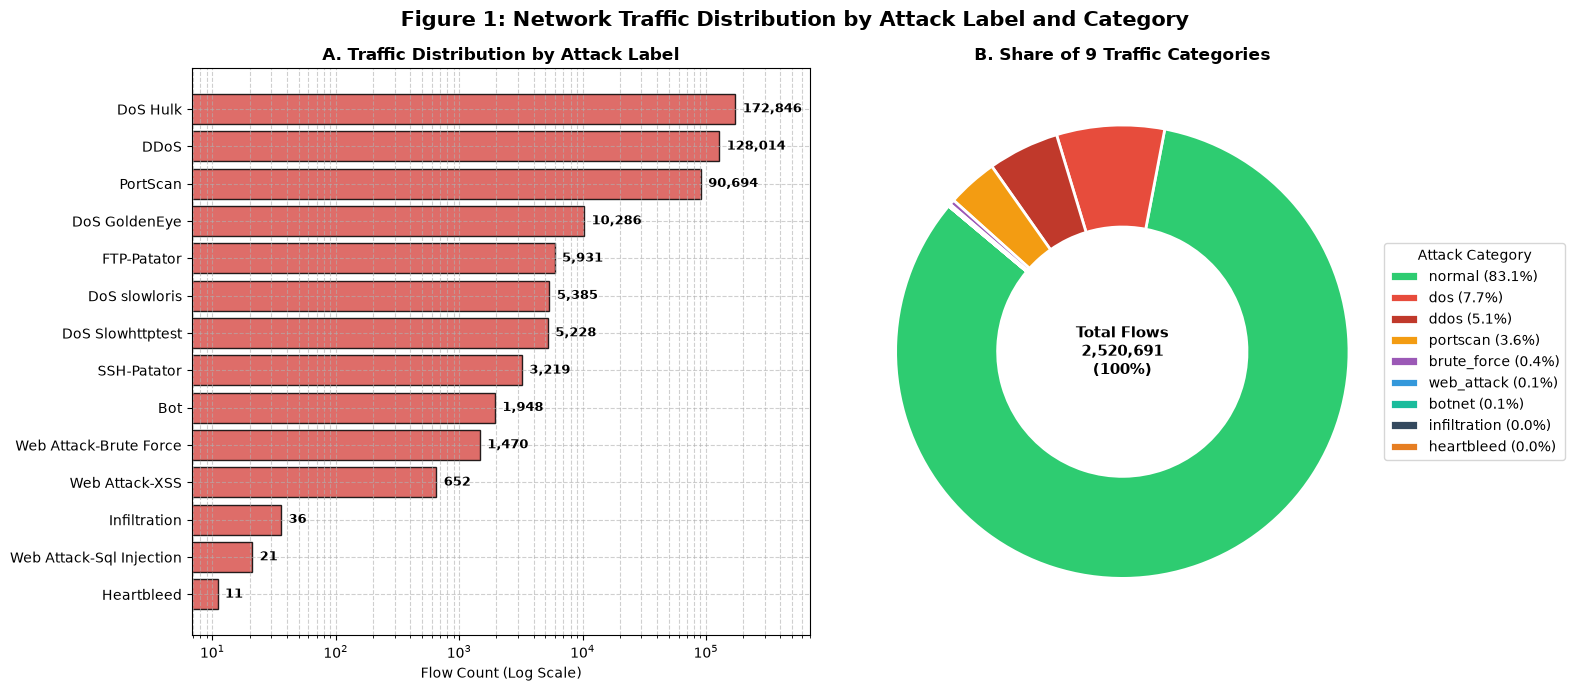

In [16]:
df_label = pd.read_csv(os.path.join(ANALYTICS_DIR, "dist_label.csv"))
df_cat = pd.read_csv(os.path.join(ANALYTICS_DIR, "dist_category.csv"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Bar chart of attack types (set_xscale("log"))
attacks_only = df_label[df_label["label"] != "BENIGN"].sort_values(by="flows", ascending=True)
bars = ax1.barh(attacks_only["label"], attacks_only["flows"], color="#d9534f", edgecolor="black", alpha=0.85)
ax1.set_xscale("log")
ax1.set_xlabel("Flow Count (Log Scale)")
ax1.set_title("A. Traffic Distribution by Attack Label", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6, which="both")

for bar in bars:
    width = bar.get_width()
    ax1.text(width * 1.15, bar.get_y() + bar.get_height() / 2, f"{int(width):,}", va="center", ha="left", fontsize=9, fontweight="bold")
ax1.set_xlim(right=ax1.get_xlim()[1] * 2.5)

# Panel 2: Donut chart of attack categories
cat_sorted = df_cat.sort_values(by="flows", ascending=False)
labels = [f"{row['attack_category']} ({row['pct']:.1f}%)" for _, row in cat_sorted.iterrows()]
colors = [COLORS.get(cat, "#7f8c8d") for cat in cat_sorted["attack_category"]]

wedges, texts = ax2.pie(
    cat_sorted["flows"],
    labels=None,
    colors=colors,
    startangle=140,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
)

total_flows = cat_sorted["flows"].sum()
ax2.text(0, 0, f"Total Flows\n{total_flows:,}\n(100%)", ha="center", va="center", fontsize=11, fontweight="bold")
ax2.legend(wedges, labels, title="Attack Category", loc="center left", bbox_to_anchor=(0.95, 0.5), frameon=True)
ax2.set_title("B. Share of 9 Traffic Categories", fontweight="bold")

plt.suptitle("Figure 1: Network Traffic Distribution by Attack Label and Category", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig1_attack_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:** 
    * Panel A (log scale) cho thấy 3 nhãn chiếm áp đảo là DoS Hulk (172,846), DDoS (128,014) và PortScan (90,694); Infiltration (36), Web Attack-Sql Injection (21), Heartbleed (11), chênh lệch khoảng 15700 lần (4 bậc độ lớn). 
    * Panel B Benign (`normal`) chiếm 83.1%, `dos` 7.7%, `ddos` 5.1%, `portscan` 3.6%; các nhóm còn lại đều ≤ 0.4%.
* **Đánh giá:** 
    * Dữ liệu bị mất cân bằng lớp nghiêm trọng ở cả mức label lẫn mức category. Cần đánh giá theo Precision/Recall/F1 từng lớp.
    * Các lớp hiếm (Infiltration, SQL Injection, Heartbleed: dưới 40 flows) không đủ mẫu để học và khó chia train/test có stratification; ML cần gộp lớp, class weighting hoặc oversampling.


### 3. Phân bố lưu lượng theo ngày và So sánh với Benign Baseline

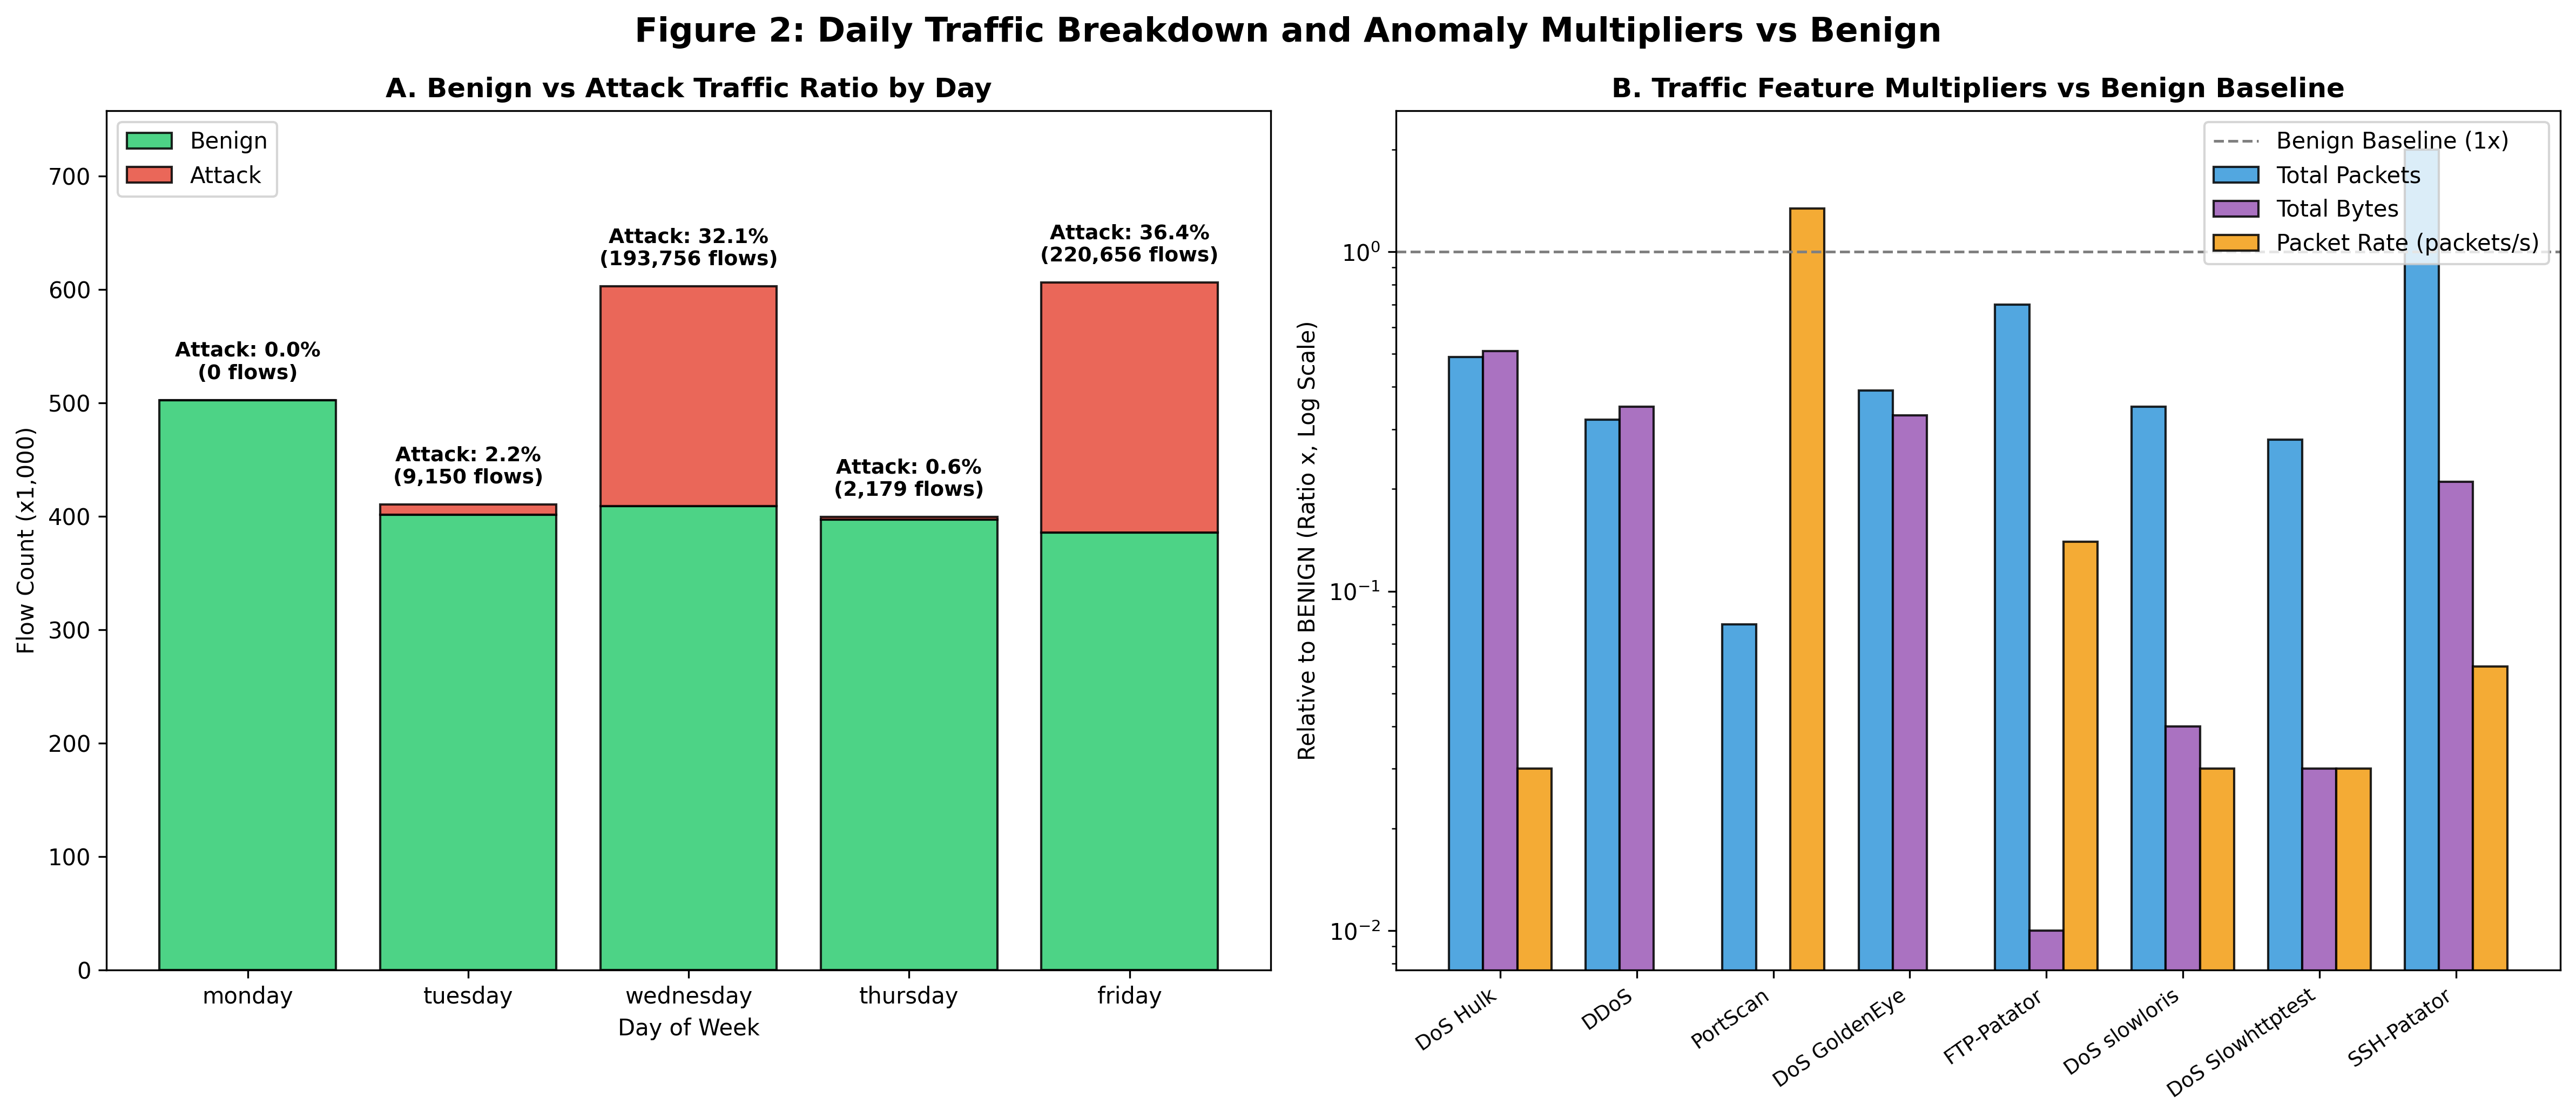

In [ ]:
df_day = pd.read_csv(os.path.join(ANALYTICS_DIR, "dist_day.csv"))
df_compare = pd.read_csv(os.path.join(ANALYTICS_DIR, "compare_vs_benign.csv"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Stacked Bar Chart by day
df_day["benign_flows"] = df_day["total_flows"] - df_day["attack_flows"]

p1 = ax1.bar(df_day["day"], df_day["benign_flows"] / 1000, label="Benign", color="#2ecc71", edgecolor="black", alpha=0.85)
p2 = ax1.bar(df_day["day"], df_day["attack_flows"] / 1000, bottom=df_day["benign_flows"] / 1000, label="Attack", color="#e74c3c", edgecolor="black", alpha=0.85)

ax1.set_xlabel("Day of Week")
ax1.set_ylabel("Flow Count (x1000)")
ax1.set_title("A. Benign vs Attack Traffic Ratio by Day", fontweight="bold")
ax1.legend(loc="upper left", frameon=True)

for idx, row in df_day.iterrows():
    total_k = row["total_flows"] / 1000
    pct = row["attack_pct"]
    ax1.text(idx, total_k + 15, f"Attack: {pct:.1f}%\n({int(row['attack_flows']):,} flows)",
             ha="center", va="bottom", fontsize=9, fontweight="semibold")
ax1.set_ylim(0, df_day["total_flows"].max() / 1000 * 1.25)

# Panel 2: Compare multipliers of attack types vs Benign
top_attacks = df_compare.head(8).copy()
metrics = ["packets_x", "bytes_x", "packet_rate_x"]
metrics_labels = ["Total Packets", "Total Bytes", "Packet Rate (packets/s)"]

x = np.arange(len(top_attacks))
width = 0.25
colors_metric = ["#3498db", "#9b59b6", "#f39c12"]

for i, col in enumerate(metrics):
    ax2.bar(x + (i - 1) * width, top_attacks[col], width, label=metrics_labels[i], color=colors_metric[i], edgecolor="black", alpha=0.85)

ax2.set_xticks(x)
ax2.set_xticklabels(top_attacks["label"], rotation=35, ha="right", fontsize=9)
ax2.set_ylabel("Relative to BENIGN (Ratio x, Log Scale)")
ax2.set_yscale("log")
ax2.axhline(1.0, color="gray", linestyle="--", linewidth=1.2, label="Benign Baseline (1x)")
ax2.set_title("B. Traffic Feature Multipliers vs Benign Baseline", fontweight="bold")
ax2.legend(loc="upper right", frameon=True)

plt.suptitle("Figure 2: Daily Traffic Breakdown and Anomaly Multipliers vs Benign",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig2_normal_vs_attack.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
    * **A:** Lượng Benign khá ổn định (~400–500K flows/ngày). Monday hoàn toàn sạch (0 attack), Tuesday 2.2% (9,150 flows), Thursday 0.6% (2,179 flows), trong khi Wednesday đạt 32.1% (193,756 flows) và Friday 36.4% (220,656 flows). Hai ngày này chiếm ~97% tổng số attack flows.
    * **B:** Trên thang log, hầu hết attack label có Total Packets và Total Bytes thấp hơn Benign (~0.01x – 0.5x); ngoại lệ là SSH-Patator có Total Packets ~2x và PortScan có Packet Rate ~1.3x so với baseline.
* **Đánh giá:** Attack traffic tập trung theo kịch bản vào Wednesday và Friday, được chèn lên nền Benign gần như không đổi. Ở mức từng flow, DoS/DDoS là rất nhiều flow nhỏ (ít packet, ít byte, packet rate thấp hơn Benign), nghĩa là dấu hiệu nằm ở số lượng flow chứ không phải kích thước mỗi flow. Vì vậy các feature thể tích riêng lẻ (packets, bytes) chưa đủ để phân biệt, cần kết hợp feature tổng hợp theo cửa sổ thời gian hoặc theo nguồn.


### 4. Temporal Analysis and Attack Progression Timeline
* **Time Interpolation:** Sử dụng row index để linear mapping các network flows lên standard Working Hours (8:00 - 17:00).
* **Periodic Pattern:** Attack traffic bùng phát mạnh vào buổi sáng (9:00 - 11:30) và đầu giờ chiều (14:00 - 16:30). Các DoS attack diễn ra liên tục, trong khi Brute Force xuất hiện dưới dạng các burst ngắn.


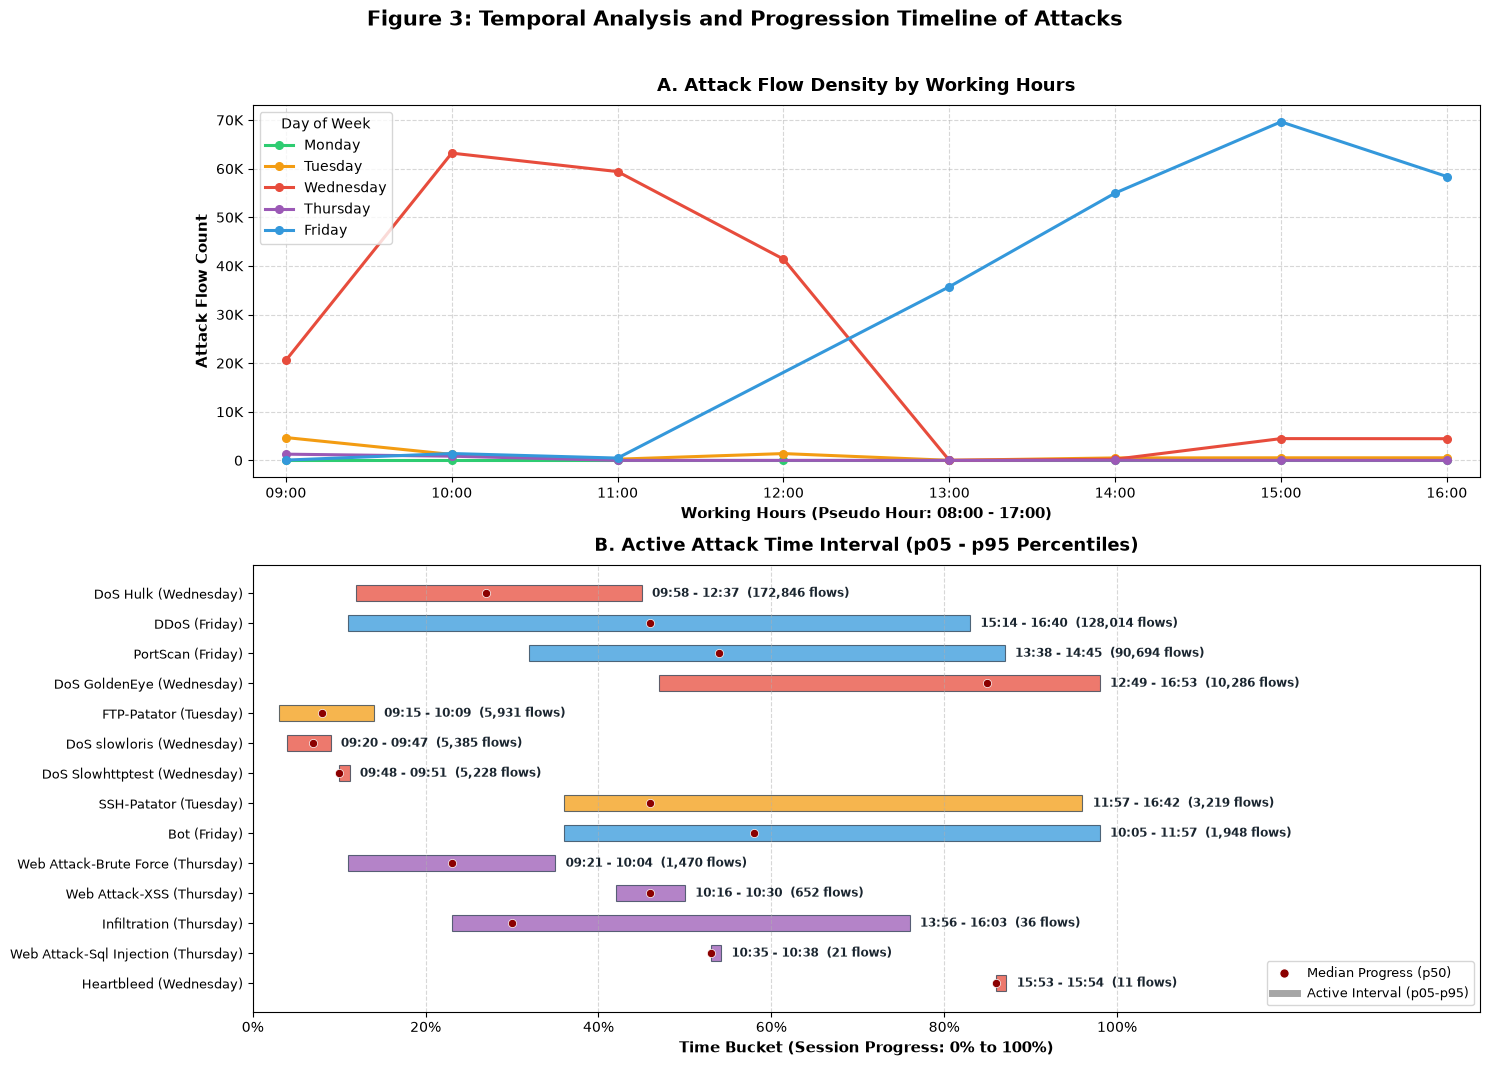

In [22]:
# 1. Đọc dữ liệu
df_hourly = pd.read_csv(os.path.join(ANALYTICS_DIR, "temporal_hourly.csv"))
df_timeline = pd.read_csv(os.path.join(ANALYTICS_DIR, "temporal_label_timeline.csv"))

# 2. Thiết lập Figure & Canvas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={'height_ratios': [1, 1.2]})

days = ["monday", "tuesday", "wednesday", "thursday", "friday"]
day_colors = {
    "monday": "#2ecc71",
    "tuesday": "#f39c12",
    "wednesday": "#e74c3c",
    "thursday": "#9b59b6",
    "friday": "#3498db"
}

# ==============================================================================
# PANEL A: Attack Flow Density by Working Hours
# ==============================================================================
for d in days:
    sub = df_hourly[df_hourly["day"] == d].sort_values("pseudo_hour")
    if not sub.empty:
        ax1.plot(
            sub["pseudo_hour"], sub["attack_flows"],
            marker="o", label=d.capitalize(),
            color=day_colors[d], linewidth=2.2, markersize=5.5
        )

# Panel A
ax1.set_xlabel("Working Hours (Pseudo Hour: 08:00 - 17:00)", fontsize=11, fontweight="semibold")
ax1.set_ylabel("Attack Flow Count", fontsize=11, fontweight="semibold")
ax1.set_title("A. Attack Flow Density by Working Hours", fontsize=13, fontweight="bold", pad=10)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(title="Day of Week", loc="upper left", frameon=True, fontsize=10, title_fontsize=10)

# Format trục X thành giờ (08:00, 09:00...) và trục Y dạng nghìn (K)
ax1.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):02d}:00"))
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y*1e-3):,}K" if y >= 1000 else f"{int(y)}"))
ax1.set_xlim(8.8, 16.2) # Tập trung vào dải giờ có dữ liệu (9h - 16h)

# ==============================================================================
# PANEL B: Timeline of Attack Campaigns
# ==============================================================================
# Sắp xếp theo flows tăng dần để cuộc tấn công lớn nhất nằm trên cùng
df_timeline = df_timeline.sort_values(by="flows", ascending=True).reset_index(drop=True)
y_pos = np.arange(len(df_timeline))
yticklabels = []

for i, row in df_timeline.iterrows():
    left = row["p05_bucket"]
    width = max(1.2, row["p95_bucket"] - row["p05_bucket"]) # Đảm bảo vạch ngắn (Heartbleed) vẫn thấy rõ
    center = row["median_bucket"]
    color = day_colors.get(row["day"].lower(), "#7f8c8d")

    # Vẽ thanh thời lượng và điểm trung vị (Median)
    ax2.barh(i, width, left=left, height=0.55, color=color, alpha=0.75, edgecolor="#2c3e50", linewidth=0.8)
    ax2.scatter(center, i, color="darkred", s=35, zorder=3, edgecolors="white", linewidths=0.5)
    
    # Text nhãn thời gian và volume
    ax2.text(
        left + width + 1.2, i,
        f"{row['p05_time']} - {row['p95_time']}  ({row['flows']:,} flows)",
        va="center", fontsize=8.5, fontweight="bold", color="#1a252f"
    )
    yticklabels.append(f"{row['label']} ({row['day'].capitalize()})")

# Tinh chỉnh trục & nhãn Panel B
ax2.set_yticks(y_pos)
ax2.set_yticklabels(yticklabels, fontsize=9.5)
ax2.set_xlabel("Time Bucket (Session Progress: 0% to 100%)", fontsize=11, fontweight="semibold")
ax2.set_title("B. Active Attack Time Interval (p05 - p95 Percentiles)", fontsize=13, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.5, axis="x")

# Giữ xlim rộng để text không bị cắt, nhưng CHỈ hiển thị ticks từ 0% đến 100%
ax2.set_xlim(0, 142)
ax2.set_xticks(np.arange(0, 101, 20))
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x)}%"))

# Thêm chú giải riêng cho điểm Median trong Panel B
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='darkred', markersize=7, label='Median Progress (p50)'),
    Line2D([0], [0], color='gray', lw=5, alpha=0.7, label='Active Interval (p05-p95)')
]
ax2.legend(handles=legend_elements, loc="lower right", frameon=True, fontsize=9)

# ==============================================================================
# Lưu và hiển thị
# ==============================================================================
plt.suptitle("Figure 3: Temporal Analysis and Progression Timeline of Attacks",
             fontsize=15, fontweight="bold", y=0.985)

# Dành khoảng đệm trên cùng cho suptitle bằng rect
plt.tight_layout(rect=[0, 0.02, 1, 0.97])

output_path = os.path.join(FIGURES_DIR, "fig3_temporal_timeline.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

* **Tổng quan:**
    * **A:** Wednesday Bùng phát mạnh từ 09:00, đạt đỉnh ~63K attack flows/giờ lúc 10:00 rồi giảm về gần 0 từ 13:00; Friday tăng dần từ 12:00 và đạt đỉnh ~70K lúc 15:00. Tuesday (~5K lúc 9:00) và Thursday (~1K) gần như phẳng, Monday bằng 0.
    * **B:** Các chiến dịch trong cùng một ngày diễn ra phần lớn tuần tự. Wednesday: DoS slowloris (09:20-09:47) $\to$ Slowhttptest (09:48-09:51) $\to$ Hulk (09:58-12:37) $\to$ GoldenEye (12:49-16:53), Heartbleed chỉ kéo dài ~1 phút (15:53-15:54). Friday: Bot (10:05-11:57) $\to$ PortScan (13:38-14:45) $\to$ DDoS (15:14-16:40). Thursday: các Web Attack (09:21-10:38) rồi Infiltration (13:56-16:03). Brute force không đồng nhất: FTP-Patator là burst ngắn (09:15-10:09), còn SSH-Patator trải dài 11:57-16:42 với chỉ 3,219 flows (kiểu tấn công né tránh ngưỡng phát hiện).
* **Đánh giá:** Attack diễn ra theo từng đợt có khung giờ riêng, nên nhãn gắn rất chặt với ngày/giờ. Nếu đưa day/hour vào feature hoặc chia train/test ngẫu nhiên, mô hình có nguy cơ data leakage (học thời điểm thay vì hành vi); nên chia theo thời gian hoặc loại bỏ feature thời gian.
* **Hạn chế:** `pseudo_time` được nội suy tuyến tính từ `seq_index`, không phải timestamp gốc, do đó giờ cụ thể chỉ mang tính tương đối; thứ tự giữa các đợt tấn công đáng tin cậy hơn giờ tuyệt đối.


### 5. Top Destination Ports và Target Service
* **Top Destination Ports**: Lưu lượng tập trung chủ yếu ở 3 cổng hàng đầu: Port 53 (DNS, ~877K flows), Port 80 (HTTP, ~542K flows) và Port 443 (HTTPS, ~470K flows). Mặc dù Port 53 có volume lớn nhất, Port 80 mới là tâm điểm tấn công với tỷ lệ độc hại lên tới 59.8%. Các port quản trị từ xa và truyền file như Port 21 (FTP, 64.2%), Port 8080 (50.5%), Port 22 (SSH, 33.5%) có volume nhỏ nhưng tỷ lệ attack chiếm ưu thế.

* **Target Services**: Các cuộc tấn công dos, web_attack, infiltration, heartbleed tập trung gần như 100% vào nhóm dịch vụ web. brute_force phân tách rõ rệt giữa dịch vụ truyền file/chứng thực (~65%, khớp với FTP-Patator) và truy cập từ xa remote_access (~35%, SSH-Patator). botnet phân bổ đa dịch vụ (~64% vào web và ~36% vào nhóm khác).


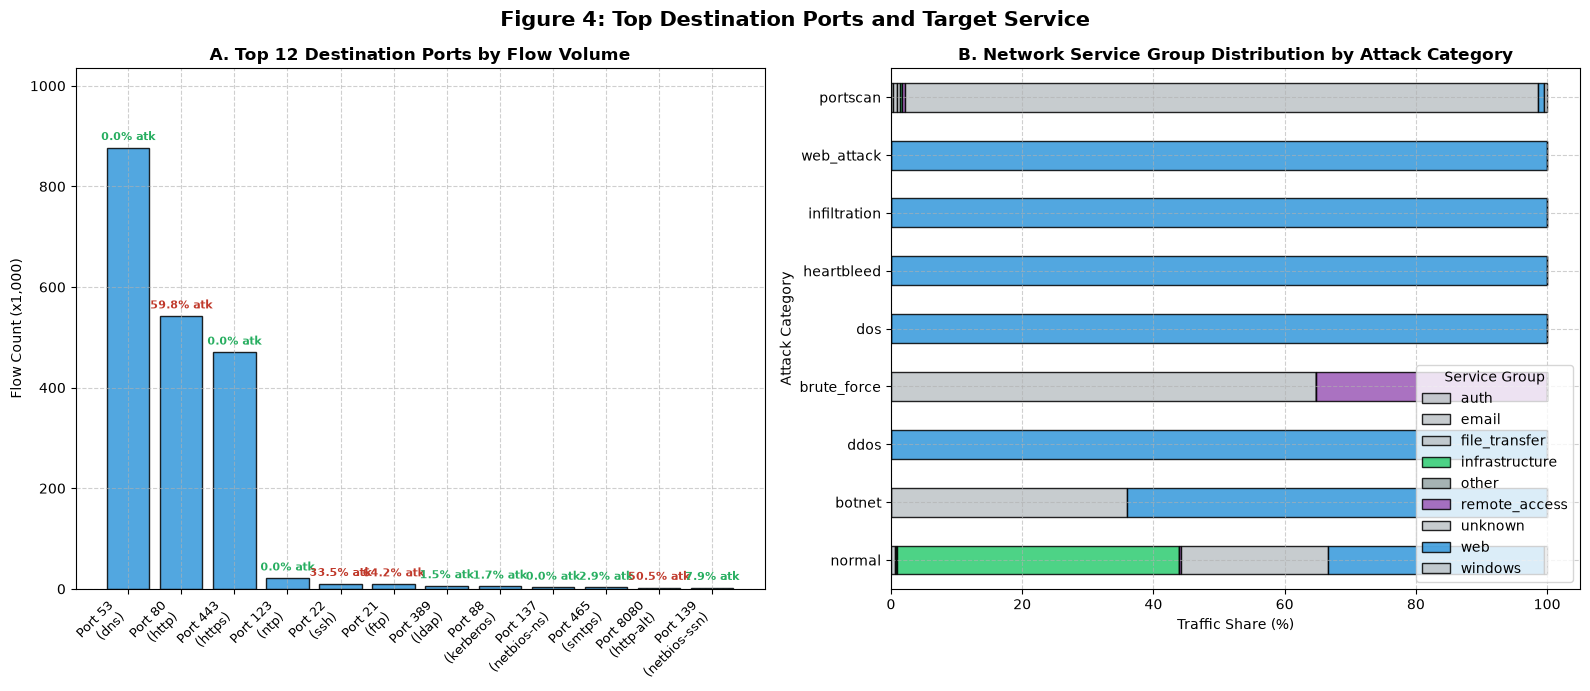

In [28]:
df_ports = pd.read_csv(os.path.join(ANALYTICS_DIR, "network_top_ports.csv"))
df_service = pd.read_csv(os.path.join(ANALYTICS_DIR, "network_service_group.csv"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Top 12 Ports
top12 = df_ports.head(12).copy()
port_labels = [f"Port {int(r['destination_port'])}\n({r['service']})" for _, r in top12.iterrows()]

bars = ax1.bar(range(len(port_labels)), top12["flows"] / 1000, color="#3498db", edgecolor="black", alpha=0.85, label="Total Flows")
ax1.set_ylabel("Flow Count (x1,000)")
ax1.set_title("A. Top 12 Destination Ports by Flow Volume", fontweight="bold")
ax1.set_xticks(range(len(port_labels)))
ax1.set_xticklabels(port_labels, rotation=45, ha="right", fontsize=9)

for bar, (_, r) in zip(bars, top12.iterrows()):
    h = bar.get_height()
    pct = r["attack_pct"]
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 10, f"{pct:.1f}% atk",
             ha="center", va="bottom", fontsize=8, fontweight="bold", color="#c0392b" if pct > 10 else "#27ae60")

ax1.set_ylim(0, top12["flows"].max() / 1000 * 1.18)
ax1.grid(True, linestyle="--", alpha=0.6)

# Panel 2: Stacked Bar theo Attack Category
pivot_service = df_service.pivot(index="attack_category", columns="service_group", values="pct").fillna(0)
pivot_service = pivot_service.loc[pivot_service.sum(axis=1).sort_values(ascending=True).index]

service_colors = {"web": "#3498db", "remote_access": "#9b59b6", "infrastructure": "#2ecc71", "data_storage": "#f39c12", "other": "#95a5a6"}
pivot_service.plot(kind="barh", stacked=True, ax=ax2, color=[service_colors.get(c, "#bdc3c7") for c in pivot_service.columns],
                   edgecolor="black", alpha=0.85)

ax2.set_xlabel("Traffic Share (%)")
ax2.set_ylabel("Attack Category")
ax2.set_title("B. Network Service Group Distribution by Attack Category", fontweight="bold")
ax2.legend(title="Service Group", loc="lower right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 4: Top Destination Ports and Target Service", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig4_top_ports_services.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
    * **A:** Port 53 (DNS) có volume lớn nhất (~877K flows) nhưng gần như không có attack (0.0%). Port 80 (HTTP, ~542K flows) có 59.8% là attack, trong khi Port 443 (HTTPS, ~470K flows) là 0.0%. Các port nhỏ nhưng tỷ lệ attack cao: Port 21 (FTP) 64.2%, Port 8080 50.5%, Port 22 (SSH) 33.5%.
    * **B:** `dos`, `ddos`, `web_attack`, `infiltration`, `heartbleed` đều ~100% vào nhóm `web`. `portscan` dàn trải, ~96% nằm ở các nhóm ngoài service group chính (thanh xám). `brute_force` tách thành ~65% (khớp tỷ lệ FTP-Patator ở Figure 1) và ~35% `remote_access` (SSH-Patator). `normal` đa dạng hơn: `infrastructure` (~43%), `web` (~33%) và các nhóm khác.
* **Đánh giá:** Attack tập trung vào web service ở Port 80 và gần như không xuất hiện trên Port 443, tức các kịch bản nhắm vào HTTP không mã hóa. Volume của port không phản ánh mức độ rủi ro; **tỷ lệ attack theo port** (Port 80/21/8080/22) là chỉ báo tốt hơn. Tuy nhiên, vì DoS, DDoS, Web Attack, Infiltration và Heartbleed cùng đổ vào Port 80, destination port không đủ để phân biệt các loại tấn công web, cần thêm feature hành vi (duration, packet rate, flag counts...).
* **Hạn chế:** Tỷ lệ attack của các port nhỏ được tính trên số mẫu ít nên độ tin cậy thấp. Nhiều service group dùng chung màu xám và legend che một phần thanh ở Panel B, nên các giá trị trên chỉ là ước lượng bằng mắt.


### 6. Độ phân tán Destination Port trong lưu lượng

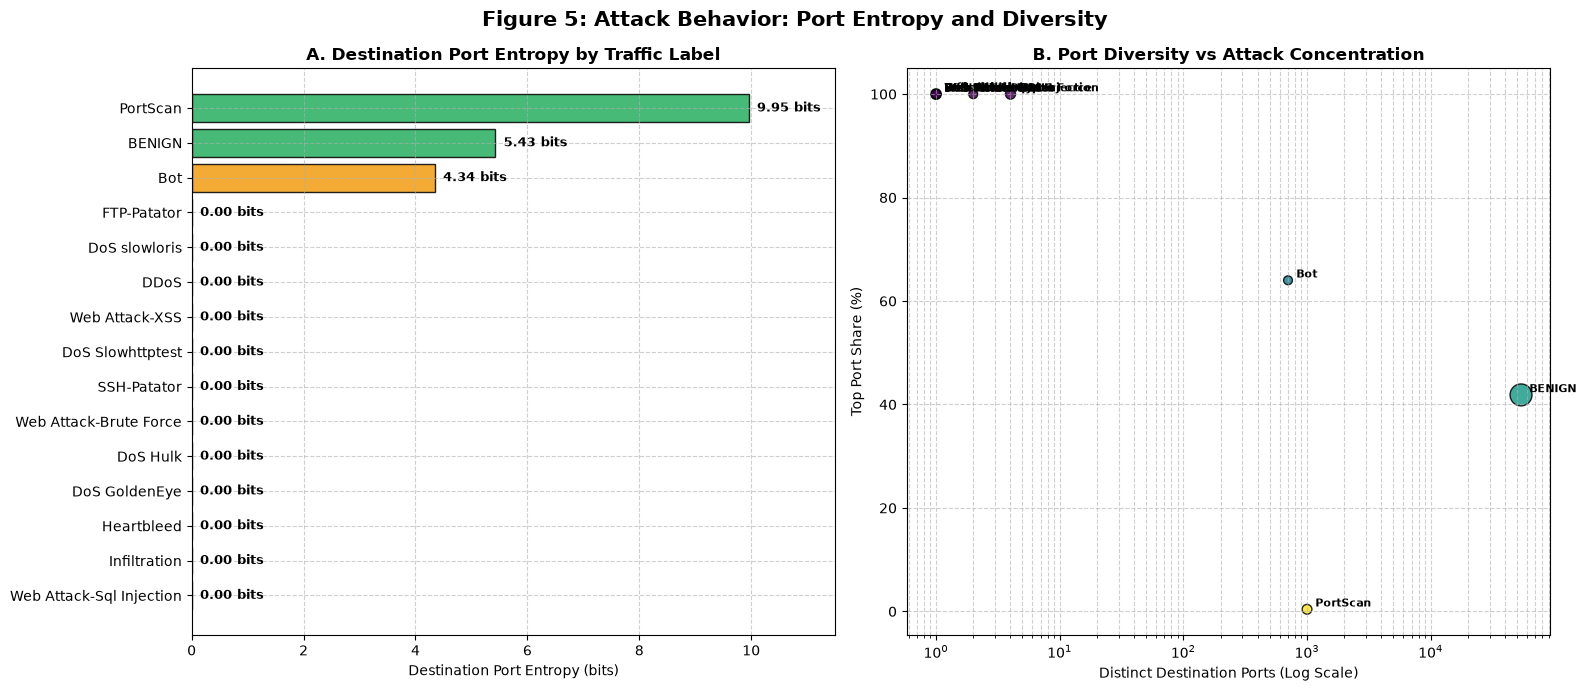

In [29]:
df_entropy = pd.read_csv(os.path.join(ANALYTICS_DIR, "network_port_diversity.csv"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Bar chart Entropy bits
sorted_ent = df_entropy.sort_values(by="port_entropy_bits", ascending=True)
colors = ["#e74c3c" if e == 0 else "#f39c12" if e < 5 else "#27ae60" for e in sorted_ent["port_entropy_bits"]]

bars = ax1.barh(sorted_ent["label"], sorted_ent["port_entropy_bits"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_xlabel("Destination Port Entropy (bits)")
ax1.set_title("A. Destination Port Entropy by Traffic Label", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.15, bar.get_y() + bar.get_height() / 2, f"{w:.2f} bits",
             va="center", ha="left", fontsize=9, fontweight="bold")
ax1.set_xlim(0, 11.5)

# Panel 2: Scatter plot Distinct Ports vs Top Port Share
ax2.scatter(df_entropy["distinct_ports"], df_entropy["top_port_share"] * 100,
            s=df_entropy["flows"] / 10000 + 40, c=df_entropy["port_entropy_bits"], cmap="viridis",
            edgecolors="black", alpha=0.85)

for _, r in df_entropy.iterrows():
    ax2.annotate(r["label"], (r["distinct_ports"], r["top_port_share"] * 100),
                 xytext=(6, 2), textcoords="offset points", fontsize=8, fontweight="semibold")

ax2.set_xscale("log")
ax2.set_xlabel("Distinct Destination Ports (Log Scale)")
ax2.set_ylabel("Top Port Share (%)")
ax2.set_title("B. Port Diversity vs Attack Concentration", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.6, which="both")

plt.suptitle("Figure 5: Attack Behavior: Port Entropy and Diversity",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig5_port_diversity_entropy.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
    * **A:**  PortScan có Port Entropy cao nhất (9.95 bits), tiếp theo là BENIGN (5.43 bits) và Bot (4.34 bits). 12/14 attack label còn lại đều có entropy = 0.00 bits.
  * **B:** 
    * **PortScan (Distributed probing):** quét ~1,000 distinct ports, top port share chỉ ~0.4% → Entropy = 9.95 bits.
    * **DoS / Brute Force và các attack nhắm mục tiêu khác:** dồn ~100% flows vào 1 port (Port 80/21/22) → Entropy = 0.00 bits.
    * **BENIGN:** ~5×10⁴ distinct ports, top port share ~42% (tương ứng Port 53). **Bot:** ~700 distinct ports, top port share ~64%.
* **Đánh giá:** Port entropy tách rõ hai hành vi đối lập: scanning (entropy cực cao, vượt cả Benign) và targeted flooding/brute force (entropy bằng 0), nên là feature mạnh để phát hiện PortScan và các tấn công đơn mục tiêu. Bot (4.34 bits) nằm gần Benign (5.43 bits) nên khó tách chỉ bằng port entropy.
* **Hạn chế:** Entropy ở đây được tính gộp trên toàn bộ flows của mỗi label. Để dùng cho detection thực tế cần tính theo từng source IP hoặc theo cửa sổ thời gian.



## II. PERFORMANCE EVALUATION (BENCHMARK B1 - B4)

### 7. Benchmark B1: Single-Node (Pandas) vs Distributed (PySpark)
* **Data Scale:** 10%, 25%, 50%, 75%, 100%, 200%, 400% original data.


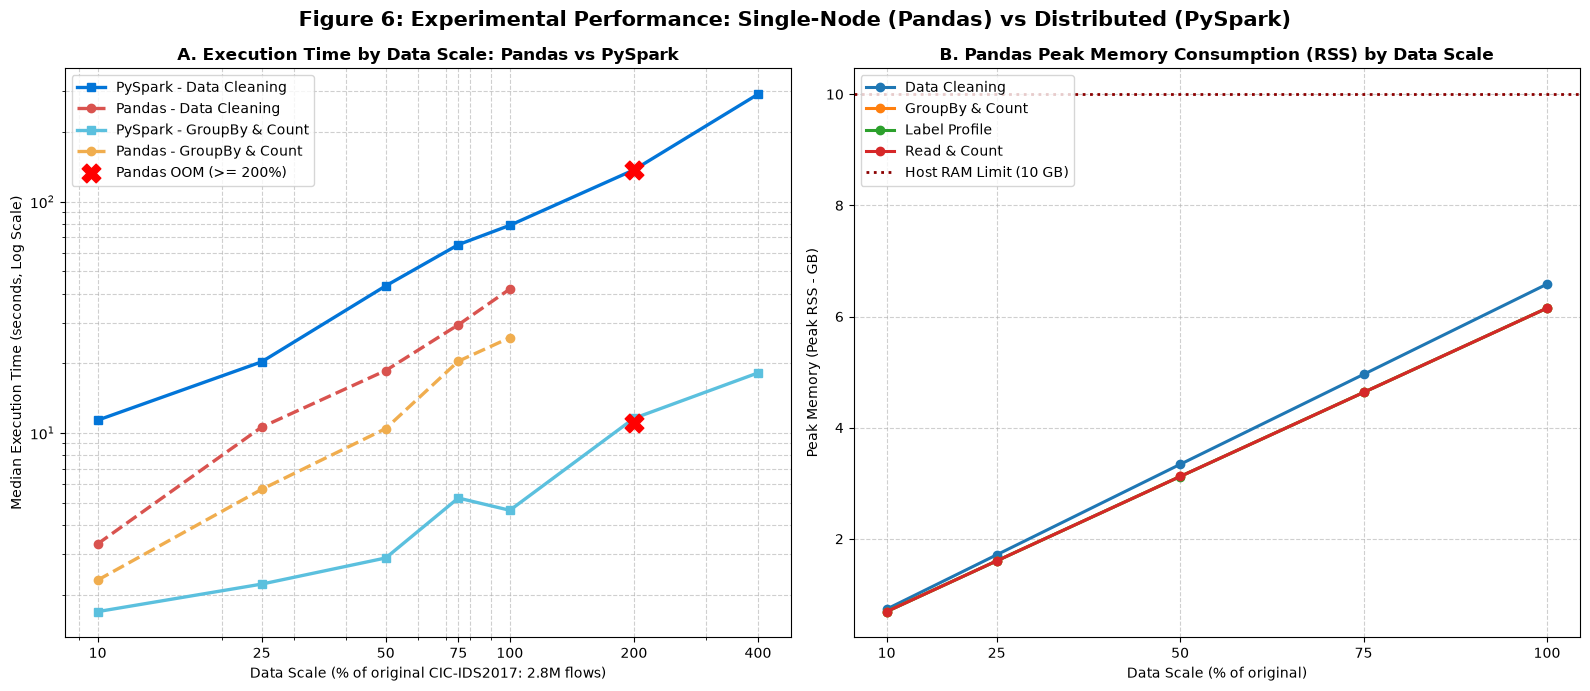

In [30]:
df_bench = pd.read_csv(BENCHMARK_PATH)
b1 = df_bench[df_bench["benchmark"] == "pandas_vs_spark"].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

tasks = ["cleaning", "groupby_count"]
task_names = {"cleaning": "Data Cleaning", "groupby_count": "GroupBy & Count"}
colors_pd = {"cleaning": "#d9534f", "groupby_count": "#f0ad4e"}
colors_sp = {"cleaning": "#0275d8", "groupby_count": "#5bc0de"}

pcts = [10, 25, 50, 75, 100, 200, 400]

for t in tasks:
    sp_sub = b1[(b1["engine"] == "spark") & (b1["task"] == t)].sort_values("data_pct")
    pd_sub = b1[(b1["engine"] == "pandas") & (b1["task"] == t)].sort_values("data_pct")

    ax1.plot(sp_sub["data_pct"], sp_sub["median_s"], marker="s", linewidth=2.4,
             color=colors_sp[t], label=f"PySpark - {task_names[t]}")

    pd_ok = pd_sub[pd_sub["status"] == "ok"]
    ax1.plot(pd_ok["data_pct"], pd_ok["median_s"], marker="o", linewidth=2.4, linestyle="--",
             color=colors_pd[t], label=f"Pandas - {task_names[t]}")

ax1.scatter([200, 200], [137, 11], color="red", marker="X", s=180, zorder=5, label="Pandas OOM (>= 200%)")

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xticks(pcts)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_xlabel("Data Scale (% of original CIC-IDS2017: 2.8M flows)")
ax1.set_ylabel("Median Execution Time (seconds, Log Scale)")
ax1.set_title("A. Execution Time by Data Scale: Pandas vs PySpark", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6, which="both")
ax1.legend(loc="upper left", frameon=True)

# Panel 2: Pandas RAM consumption (Peak Memory RSS - MB)
pd_tasks = ["cleaning", "groupby_count", "label_profile", "read_count"]
pd_names = {"cleaning": "Data Cleaning", "groupby_count": "GroupBy & Count",
            "label_profile": "Label Profile", "read_count": "Read & Count"}

for t in pd_tasks:
    sub = b1[(b1["engine"] == "pandas") & (b1["task"] == t) & (b1["status"] == "ok")].sort_values("data_pct")
    ax2.plot(sub["data_pct"], sub["peak_mem_mb"] / 1024, marker="o", linewidth=2.2, label=pd_names.get(t, t))

ax2.axhline(10.0, color="darkred", linestyle=":", linewidth=2, label="Host RAM Limit (10 GB)")

ax2.set_xlabel("Data Scale (% of original)")
ax2.set_ylabel("Peak Memory (Peak RSS - GB)")
ax2.set_title("B. Pandas Peak Memory Consumption (RSS) by Data Scale", fontweight="bold")
ax2.set_xticks([10, 25, 50, 75, 100])
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper left", frameon=True)

plt.suptitle("Figure 6: Experimental Performance: Single-Node (Pandas) vs Distributed (PySpark)",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig6_pandas_vs_spark.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
    * **A:** Từ 10% đến 100% dữ liệu, Pandas Data Cleaning nhanh hơn PySpark (~3.3 s so với ~11 s ở 10%; ~42 s so với ~78 s ở 100%). Ngược lại, ở GroupBy & Count PySpark đã nhanh hơn ngay từ đầu (~1.7 s so với ~2.3 s ở 10%; ~4.7 s so với ~26 s ở 100%). Tại 200% và 400%, Pandas bị Out of Memory: vượt giới hạn 10 GB RAM nên không có kết quả (ký hiệu X), trong khi PySpark vẫn hoàn thành: Data Cleaning ~137 s (200%) và ~290 s (400%), GroupBy & Count ~11 s (200%) và ~18 s (400%).
    * **B:** Peak RSS của Pandas tăng gần tuyến tính theo dung lượng dữ liệu: Data Cleaning từ ~0.7 GB (10%) lên ~6.6 GB (100%), Read & Count ~6.1 GB (100%); các task còn lại trùng hoặc sát hai đường này. Ngoại suy tuyến tính, 200% cần ~13 GB, vượt Host RAM Limit 10 GB, phù hợp với breaking point OOM tại 200% (5.66M records).
* **Đánh giá:** Ở 100% (2.8M flows) Pandas đã dùng ~66% RAM (6.6/10 GB), chỉ còn ~3.4 GB headroom, nên single-node chỉ phù hợp đến quy mô này. Lợi thế của PySpark không nằm ở tốc độ trên dữ liệu nhỏ (overhead JVM/DAG scheduling thể hiện rõ ở Data Cleaning) mà ở khả năng mở rộng: Data Cleaning chỉ tăng ~2.1x khi dữ liệu tăng gấp đôi (200% $\to$ 400%) và không bị giới hạn bởi RAM của một node.


### 8. Benchmark B2 vs B3: Storage Footprint (CSV vs Parquet) & SQL Query Engines (Hive on YARN vs Spark SQL)
* **Storage Footprint:** Columnar Parquet (349.2 MB) **tiết kiệm 71.9% HDFS storage** so với raw CSV (1,243.2 MB) nhờ Snappy compression và columnar storage format.
* **SQL Query Benchmark:** Spark SQL nhanh hơn Hive on MapReduce từ **15x đến 50x** trên 7 query types (Filter, Join, GroupBy, Window Function, Aggregation).
  * Ví dụ: Window Function mất **56.68 s trên Hive MapReduce**, nhưng chỉ mất **1.33 s trên Spark SQL (speedup 42.6x)**.


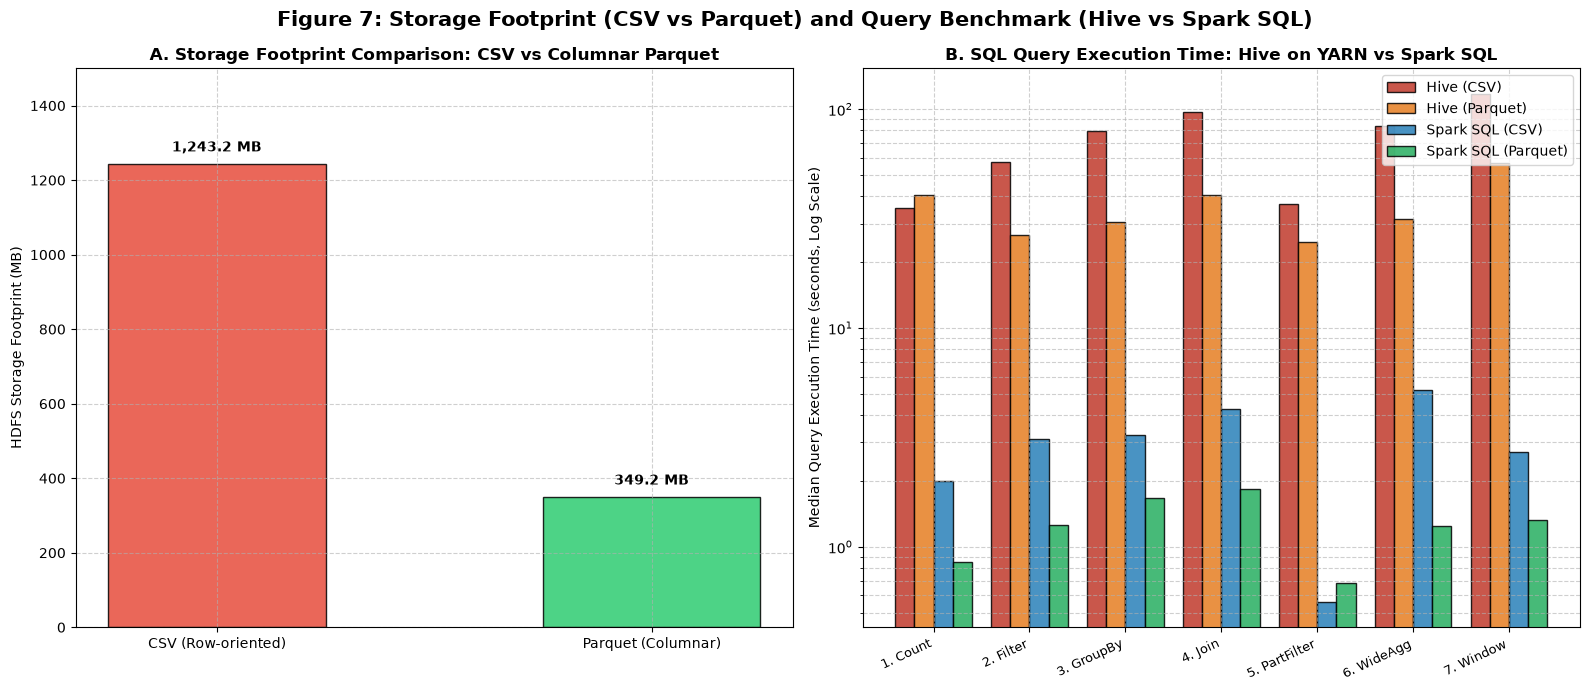

In [31]:
b_sql = df_bench[df_bench["benchmark"] == "sql_engine"].copy()

parquet_size_mb = 349.2
csv_size_mb = 1243.2
if os.path.exists(TRANSFORM_REPORT):
    try:
        with open(TRANSFORM_REPORT, encoding="utf-8") as f:
            r_json = json.load(f)
            parquet_size_mb = r_json.get("size_mb_parquet", parquet_size_mb)
            csv_size_mb = r_json.get("size_mb_csv", csv_size_mb)
    except Exception:
        pass

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Storage footprint
formats = ["CSV (Row-oriented)", "Parquet (Columnar)"]
sizes = [csv_size_mb, parquet_size_mb]
colors_fmt = ["#e74c3c", "#2ecc71"]

bars1 = ax1.bar(formats, sizes, color=colors_fmt, edgecolor="black", width=0.5, alpha=0.85)
ax1.set_ylabel("HDFS Storage Footprint (MB)")
ax1.set_title("A. Storage Footprint Comparison: CSV vs Columnar Parquet", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6)

reduction_pct = (csv_size_mb - parquet_size_mb) / csv_size_mb * 100
for bar, s in zip(bars1, sizes):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 25, f"{s:,.1f} MB",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

ax1.set_ylim(0, 1500)

# Panel 2: Performance of 7 SQL queries (Hive on YARN vs Spark SQL)
queries = ["count", "filter", "groupby_agg", "join", "partition_filter", "wide_agg", "window"]
query_names = {
    "count": "1. Count",
    "filter": "2. Filter",
    "groupby_agg": "3. GroupBy",
    "join": "4. Join",
    "partition_filter": "5. PartFilter",
    "wide_agg": "6. WideAgg",
    "window": "7. Window"
}

hive_parquet, hive_csv, spark_parquet, spark_csv = [], [], [], []
for q in queries:
    hp = b_sql[(b_sql["engine"] == "hive") & (b_sql["task"] == q) & (b_sql["table"] == "flows")]["median_s"].values
    hc = b_sql[(b_sql["engine"] == "hive") & (b_sql["task"] == q) & (b_sql["table"] == "flows_csv")]["median_s"].values
    sp = b_sql[(b_sql["engine"] == "spark_sql") & (b_sql["task"] == q) & (b_sql["table"] == "flows")]["median_s"].values
    sc = b_sql[(b_sql["engine"] == "spark_sql") & (b_sql["task"] == q) & (b_sql["table"] == "flows_csv")]["median_s"].values

    hive_parquet.append(hp[0] if len(hp) else 0)
    hive_csv.append(hc[0] if len(hc) else 0)
    spark_parquet.append(sp[0] if len(sp) else 0)
    spark_csv.append(sc[0] if len(sc) else 0)

x = np.arange(len(queries))
w = 0.2

ax2.bar(x - 1.5 * w, hive_csv, w, label="Hive (CSV)", color="#c0392b", edgecolor="black", alpha=0.85)
ax2.bar(x - 0.5 * w, hive_parquet, w, label="Hive (Parquet)", color="#e67e22", edgecolor="black", alpha=0.85)
ax2.bar(x + 0.5 * w, spark_csv, w, label="Spark SQL (CSV)", color="#2980b9", edgecolor="black", alpha=0.85)
ax2.bar(x + 1.5 * w, spark_parquet, w, label="Spark SQL (Parquet)", color="#27ae60", edgecolor="black", alpha=0.85)

ax2.set_xticks(x)
ax2.set_xticklabels([query_names[q] for q in queries], rotation=25, ha="right", fontsize=9.5)
ax2.set_ylabel("Median Query Execution Time (seconds, Log Scale)")
ax2.set_yscale("log")
ax2.set_title("B. SQL Query Execution Time: Hive on YARN vs Spark SQL", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.6, which="both")
ax2.legend(loc="upper right", frameon=True)

plt.suptitle("Figure 7: Storage Footprint (CSV vs Parquet) and Query Benchmark (Hive vs Spark SQL)",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig7_storage_and_query.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
    * **A:** Parquet (349.2 MB) nhỏ hơn CSV (1243.2 MB) khoảng 3.6 lần (tiết kiệm 71.9% HDFS storage) nhờ thuật toán nén Snappy kết hợp cơ chế lưu trữ theo cột.
    * **B:** Spark SQL vượt trội hơn Hive on MapReduce ở cả 7 loại query. So sánh trực tiếp trên định dạng tối ưu Parquet: Count ~40.5s so với ~0.85s (~47.7x), PartFilter ~24.8s so với ~0.68s (~36.5x), Window 56.68s so với 1.33s (42.6x), còn Filter/GroupBy/Join/WideAgg nhanh hơn từ 18.2x đến 25.3x. Toàn bộ 7 query trên Spark SQL (Parquet) đều hoàn thành trong mức cận tức thời (~0.68–1.83s), trong khi Hive on MapReduce luôn có độ trễ nền $\ge$ 24.8s.
* **Đánh giá:** 
    * Hive on MapReduce chịu độ trễ cố định lớn (~25-40s) kể cả với câu lệnh đơn giản như Count do chi phí khởi tạo YARN container, cấp phát JVM và ghi trung gian xuống đĩa, chỉ thích hợp cho tác vụ batch/ETL nền định kỳ; ngược lại Spark SQL (xử lý in-memory và DAG execution) hoàn toàn đáp ứng tốt phân tích tương tác thời gian thực.
    * Định dạng Parquet mang lại hiệu quả tăng tốc rõ rệt trên cả hai engine: trên Spark SQL tăng từ 2x đến 4.2x (rõ nhất ở WideAgg: 5.22s $\to$ 1.25s); trên Hive tăng tốc từ 2.1x đến 2.7x ở toàn bộ các query nặng (Filter, GroupBy, Join, WideAgg, Window).
    * Hai ngoại lệ không có sự khác biệt rõ rệt: **Count trên Hive** (~35.5s CSV vs ~40.5s Parquet) do thời gian khởi tạo container của YARN chiếm trọn thời gian chạy; và **PartFilter trên Spark SQL** (~0.56s CSV vs ~0.68s Parquet) do cơ chế **Partition Pruning** đã loại bỏ phần lớn dữ liệu không cần thiết, thời gian còn lại chủ yếu là chi phí lập kế hoạch truy vấn của Driver.
    * **Kết luận:** Mô hình kết hợp **Spark SQL + Parquet** là giải pháp tối ưu toàn diện nhất, vừa cắt giảm hơn 70% dung lượng HDFS vừa tăng tốc độ xử lý dữ liệu từ hàng chục lần đến gần 50 lần.

### 9. Benchmark B4: Scalability and Parallel Speedup of Apache Spark
* **Experiment Setup:** Allocate 1, 2, 4 CPU Cores trên 100% và 200% data scale


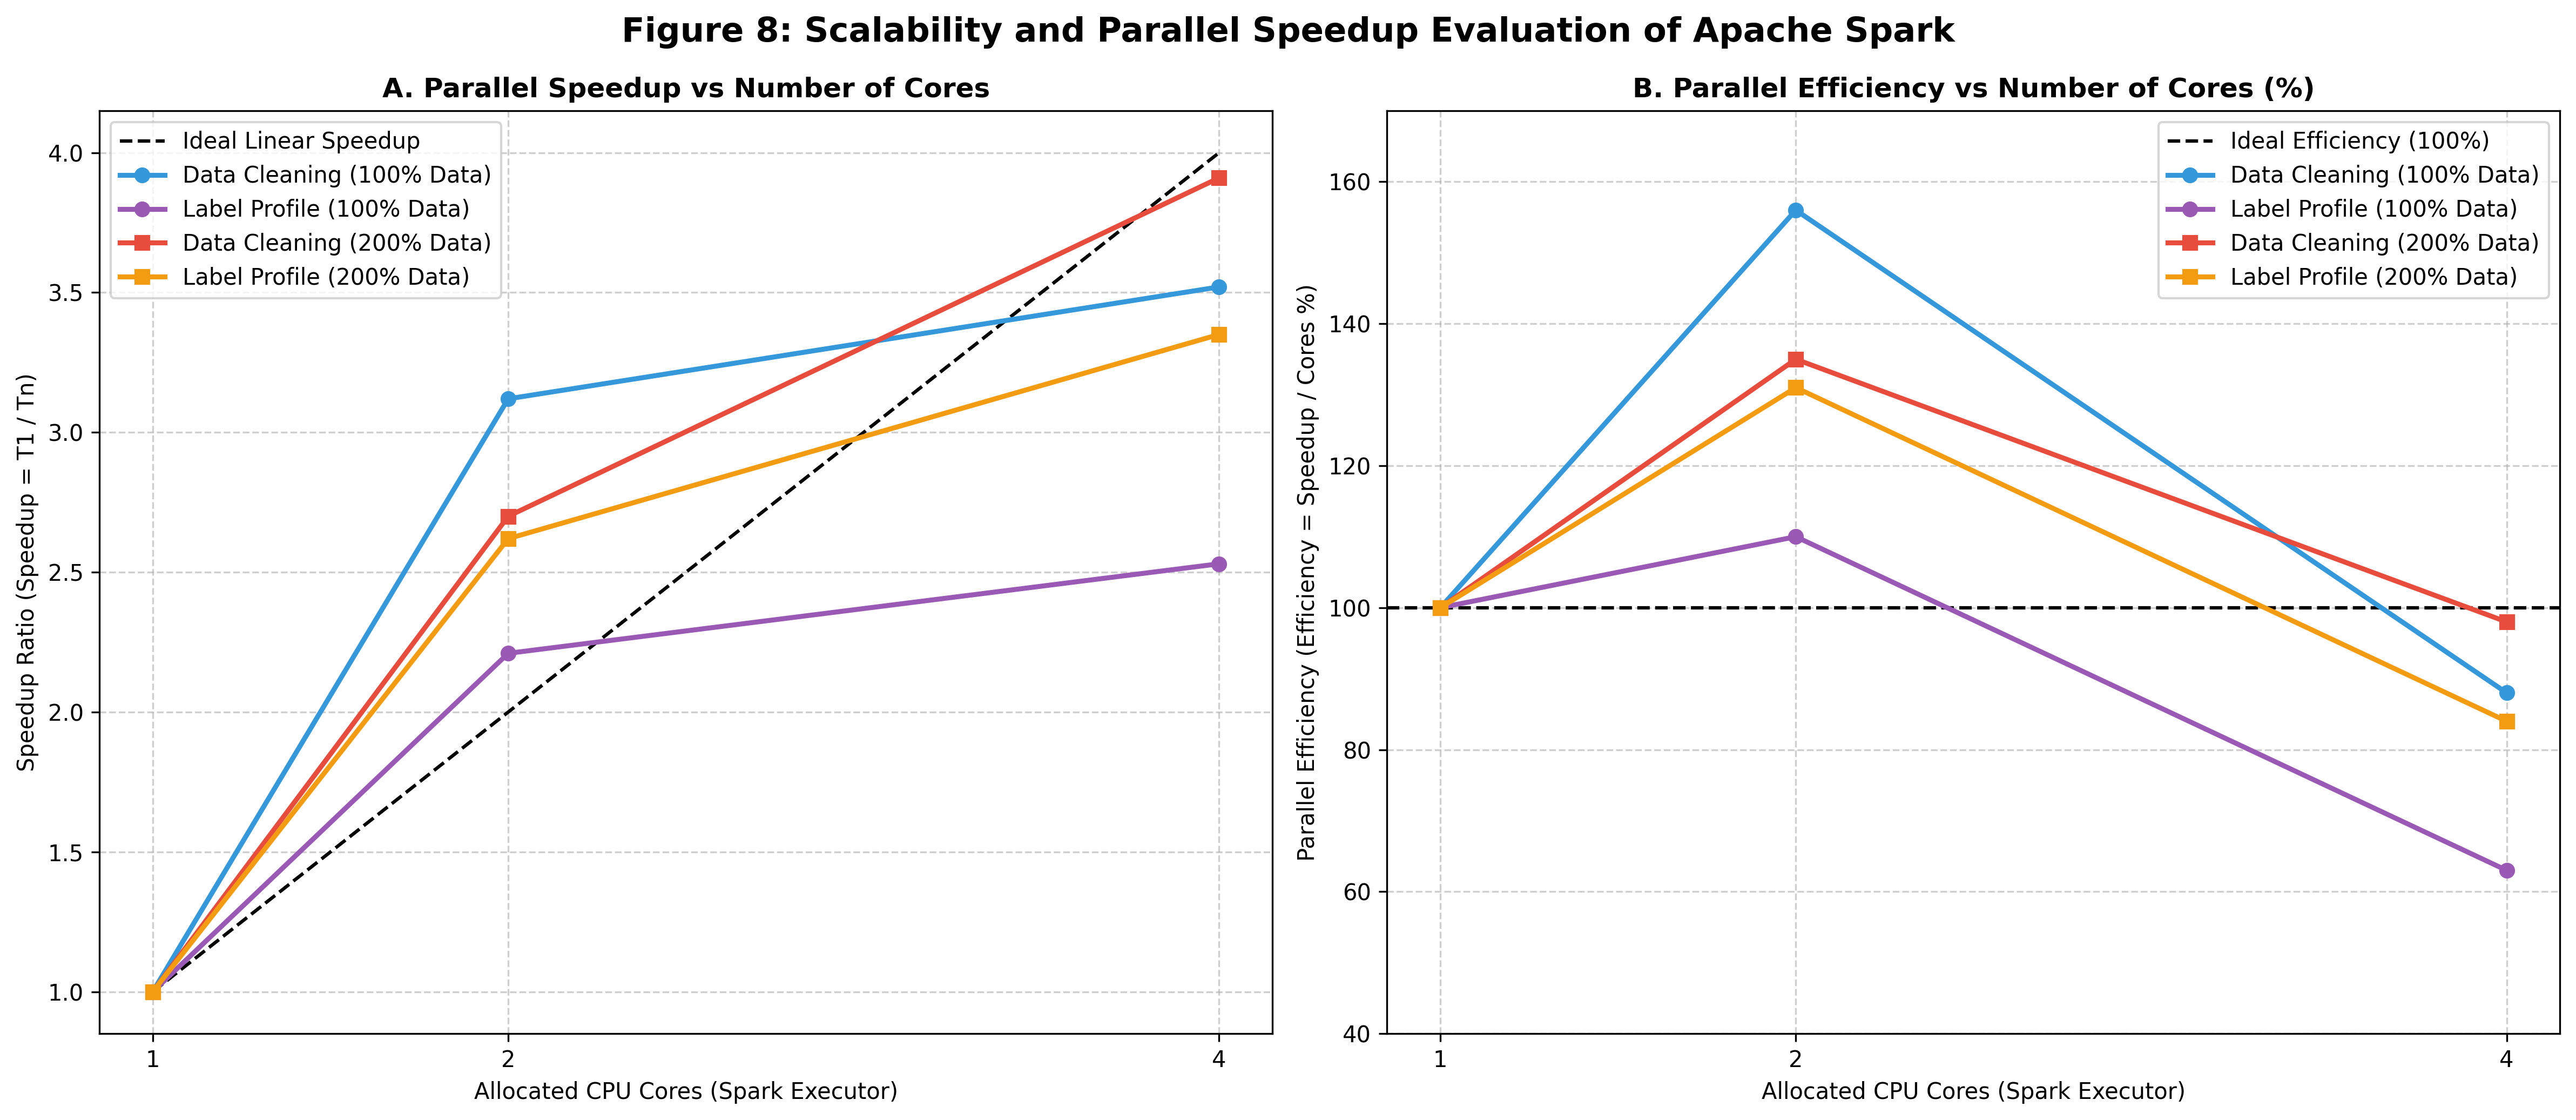

In [ ]:
b4 = df_bench[df_bench["benchmark"] == "scalability"].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
cores = [1, 2, 4]

# Panel 1: Speedup vs Cores
ax1.plot(cores, cores, color="black", linestyle="--", linewidth=1.5, label="Ideal Linear Speedup")

tasks = ["cleaning", "label_profile"]
task_names = {"cleaning": "Data Cleaning", "label_profile": "Label Profile"}
markers = {100: "o", 200: "s"}
colors_pct = {100: "#3498db", 200: "#e74c3c"}

for pct in [100, 200]:
    for t in tasks:
        sub = b4[(b4["data_pct"] == pct) & (b4["task"] == t)].sort_values("cores")
        label = f"{task_names[t]} ({pct}% Data)"
        color = colors_pct[pct] if t == "cleaning" else "#9b59b6" if pct == 100 else "#f39c12"
        ax1.plot(sub["cores"], sub["speedup"], marker=markers[pct], linewidth=2.2,
                 color=color, label=label)

ax1.set_xticks(cores)
ax1.set_xlabel("Allocated CPU Cores (Spark Executor)")
ax1.set_ylabel("Speedup Ratio (Speedup = T1 / Tn)")
ax1.set_title("A. Parallel Speedup vs Number of Cores", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper left", frameon=True)

# Panel 2: Parallel Efficiency (%) vs Cores
ax2.axhline(100, color="black", linestyle="--", linewidth=1.5, label="Ideal Efficiency (100%)")

for pct in [100, 200]:
    for t in tasks:
        sub = b4[(b4["data_pct"] == pct) & (b4["task"] == t)].sort_values("cores")
        label = f"{task_names[t]} ({pct}% Data)"
        color = colors_pct[pct] if t == "cleaning" else "#9b59b6" if pct == 100 else "#f39c12"
        eff_pct = sub["efficiency"] * 100
        ax2.plot(sub["cores"], eff_pct, marker=markers[pct], linewidth=2.2,
                 color=color, label=label)

ax2.set_xticks(cores)
ax2.set_xlabel("Allocated CPU Cores (Spark Executor)")
ax2.set_ylabel("Parallel Efficiency (Efficiency = Speedup / Cores %)")
ax2.set_title("B. Parallel Efficiency vs Number of Cores (%)", fontweight="bold")
ax2.set_ylim(40, 170)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.suptitle("Figure 8: Scalability and Parallel Speedup Evaluation of Apache Spark",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig8_scalability.png"), dpi=300, bbox_inches="tight")
plt.show()


* **Tổng quan:**
  * **A:** Tại 4 cores, speedup đạt ~3.91x với Data Cleaning 200% (gần ideal 4x), ~3.52x với Data Cleaning 100%, ~3.35x với Label Profile 200% và ~2.53x với Label Profile 100%.
  * **B:** Parallel Efficiency ở 4 cores là ~98% (Cleaning 200%), ~88% (Cleaning 100%), ~84% (Label Profile 200%) và ~63% (Label Profile 100%). Ở 2 cores, efficiency vượt 100% (~110–156%), speedup siêu tuyến tính.
* **Đánh giá:**
  * Data scale càng lớn thì efficiency càng cao (Cleaning: 88% $\to$ 98%; Label Profile: 63% $\to$ 84%), vì overhead cố định (JVM startup, scheduling, shuffle) được chia đều trên khối lượng tính toán lớn hơn. Spark phát huy hiệu quả khi data volume đủ lớn.
  * Label Profile (aggregation, nhiều khả năng có shuffle) scale kém hơn Data Cleaning ở cùng data scale.
  * Efficiency > 100% ở 2 cores khó là tăng tốc thật sự; nhiều khả năng baseline 1 core bị chậm bất thường (memory pressure/GC, cold cache) làm speedup bị thổi phồng.
* **Kết luận thận trọng:** Chỉ có thể nói Spark scale gần tuyến tính với Data Cleaning ở 200% (3.91x, 97.8%), chưa khái quát cho mọi tác vụ. Cần thêm số lần lặp và thêm mức cores (8, 16) để kết luận chắc hơn.
